# Collection-to-availability delay

Neural data only. Reads `stitched_file_audit.py`'s output CSV and looks at the delay between when a stitched task's data was actually collected (`data_end_utc`) and when the stitched file itself became available on disk (`last_modified_utc`) - i.e. how long after a recording ends before its stitched file is ready.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os

STITCHED_AUDIT_CSV = '../phi-data/stitch_timing.csv'
SOURCE_AUDIT_CSV = '../phi-data/source_timing.csv'
VIDEO_AUDIT_CSV = '../phi-data/video_file_timing.csv'
NEURAL_COLOR = '#2a78d6'
VIDEO_COLOR = '#eb6834'
OUT_FOLDER = r'D:\Work\Publication\EMU247 2026\availability fig'

In [2]:
def format_time_cols(df, data_end_col='data_end_utc', last_mod_col='last_modified_utc'):
    df[data_end_col] = pd.to_datetime(df[data_end_col], format='ISO8601', utc=True)
    df[last_mod_col] = pd.to_datetime(df[last_mod_col], format='ISO8601', utc=True)
    return df


stitched = format_time_cols(pd.read_csv(STITCHED_AUDIT_CSV))
sources = format_time_cols(pd.read_csv(SOURCE_AUDIT_CSV))
videos = format_time_cols(pd.read_csv(VIDEO_AUDIT_CSV))

print(f'{len(sources)} neural source files across {sources["emu_id"].nunique()} patient(s)')
print(f'{len(videos)} video source files across {videos["emu_id"].nunique()} patient(s)')
print(f'{len(stitched)} stitched task(s) across {stitched["emu_id"].nunique()} patient(s)')


2000 neural source files across 30 patient(s)
2903 video source files across 28 patient(s)
3379 stitched task(s) across 29 patient(s)


## Per-patient distribution of collection-to-availability delay

In [3]:
SKIP_PATIENT = ['YFY', 'YFS', 'YFT']
LAST_REBUILD = 'YFG'
NOMINAL_PATIENTS = ['YFN', 'YFP', 'YFQ', 'YFR', 'YFS', 'YFT', 'YFZ']
DELAY_RANGE = [0, 10**3]


def prep_delays(timing_df):
    # Get only rows that have enough data to calcualte a delay
    has_delay = timing_df['data_end_utc'].notna() & timing_df['last_modified_utc'].notna()
    delay = timing_df.loc[has_delay].copy()

    delay['delay_hours'] = (delay['last_modified_utc'] - delay['data_end_utc']).dt.total_seconds() / 3600
    return delay


def filter_delays(delay_df, since_rebuild=False, nominal_only=False, remove_skip=False, in_range=False):
    if since_rebuild:
        rebuild_pt = since_rebuild if isinstance(since_rebuild, str) else LAST_REBUILD
        all_patients = np.array(sorted(sources['emu_id'].unique()))  # Fetch list of all patients from unfiltered data
        indexes = np.arange(len(all_patients))
        try:
            pivot =  np.argwhere(all_patients == rebuild_pt)[0, 0]
        except IndexError:
            raise KeyError(f'Passed patient ({rebuild_pt}) not found in the list of all patients')
        after = np.array(indexes) >= pivot
        to_keep = np.array(all_patients)[after]    # All patient IDXs since the last rebuild
        delay_df = delay_df.loc[[p in to_keep for p in delay_df['emu_id']]].copy()
        print(f'Filtered out the most recent {len(to_keep)} patients')

    if remove_skip:
        # Exclude skipped patients
        skip = np.zeros_like(delay_df['emu_id']).astype(bool)
        for s in SKIP_PATIENT:
            skip = np.logical_or(skip, delay_df['emu_id'] == s)
        delay_df = delay_df[np.logical_not(skip)]

    if nominal_only:
        delay_df = delay_df.loc[[p in NOMINAL_PATIENTS for p in delay_df['emu_id']]].copy()

    if in_range:
        delay_df = delay_df[np.logical_and(DELAY_RANGE[0] < delay_df['delay_hours'], delay_df['delay_hours'] < DELAY_RANGE[1])]

    return delay_df



neural_delay = filter_delays(prep_delays(sources), since_rebuild=True)
videos_delay = filter_delays(prep_delays(videos), since_rebuild=True)

stitch_delay = filter_delays(prep_delays(stitched), since_rebuild='YGA', remove_skip=True, in_range=True)

print(f'{len(videos_delay)} video delays between {round(videos_delay["delay_hours"].min(), 2)} and {round(videos_delay["delay_hours"].max(), 2)} hours')
print(f'{len(neural_delay)} neural delays between {round(neural_delay["delay_hours"].min(), 2)} and {round(neural_delay["delay_hours"].max(), 2)} hours')

Filtered out the most recent 22 patients
Filtered out the most recent 22 patients
Filtered out the most recent 2 patients
2396 video delays between 0.18 and 711.84 hours
1518 neural delays between 0.19 and 90.97 hours


## Nominal collection-to-availability delay, pooled across patients

5.5% of neural data arrived after 0.5 hours
2.1% of neural data arrived after 24 hours
18.5% of video data arrived after 0.5 hours
12.9% of video data arrived after 24 hours


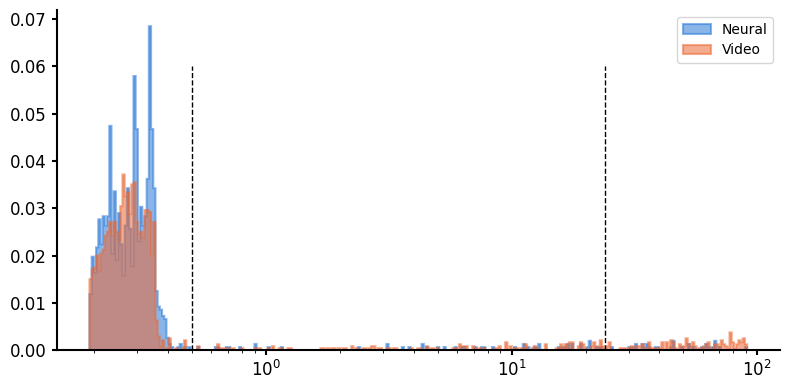

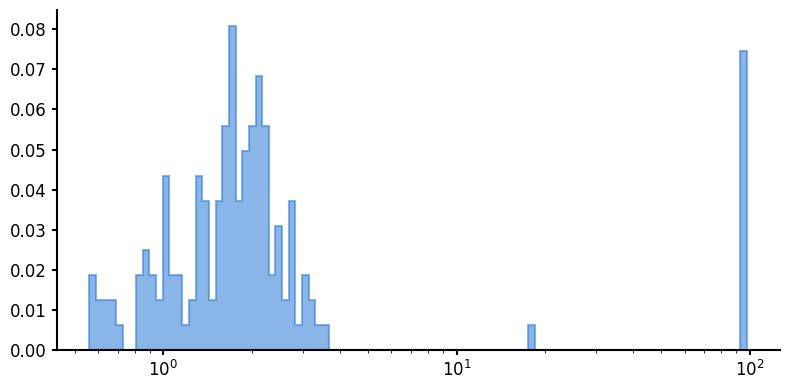

In [4]:
from plotting_utils import hist_ax, style_hist_axes, stepfilled_hist

lower = 0.5
upper = 24

def plot_delays(delay_df, label, color, plot_bins=None):
    weights = np.ones_like(delay_df['delay_hours']) / len(delay_df['delay_hours'])
    ax.hist(
        delay_df['delay_hours'], weights=weights, bins=plot_bins, histtype='stepfilled',
        color=color, edgecolor=color, alpha=0.55, linewidth=1.5, label=label
    )
    ax.set_xscale('log')

def calc_slow_data_prop(delay_df, threshold=1.0, label=None):
    total_rows = len(delay_df)
    big_delay = len(delay_df[delay_df['delay_hours'] > threshold])
    prop = 100*(big_delay/total_rows)
    print(f'{round(prop, 1)}% of {label} data arrived after {threshold} hours')

lmin, lmax = np.log10(neural_delay['delay_hours'].min()), np.log10(neural_delay['delay_hours'].max())
log_bins = np.logspace(lmin, lmax, num=300)

calc_slow_data_prop(neural_delay, label='neural', threshold=lower)
calc_slow_data_prop(neural_delay, label='neural', threshold=upper)
calc_slow_data_prop(videos_delay, label='video', threshold=lower)
calc_slow_data_prop(videos_delay, label='video', threshold=upper)

fig, ax = plt.subplots(figsize=(8, 4))
plot_delays(neural_delay, 'Neural', NEURAL_COLOR, plot_bins=log_bins)
plot_delays(videos_delay, 'Video', VIDEO_COLOR, plot_bins=log_bins)
plt.plot([upper, upper], [0,0.06], color='black', linestyle='--', linewidth=1.0)
plt.plot([lower, lower], [0,0.06], color='black', linestyle='--', linewidth=1.0)
# plt.xlabel('Delay (hours)')
style_hist_axes(ax)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_FOLDER, 'source_data_delay.png'), dpi=150)
plt.show()


lmin, lmax = np.log10(stitch_delay['delay_hours'].min()), np.log10(stitch_delay['delay_hours'].max())
log_bins = np.logspace(lmin, lmax, num=100)
fig, ax = plt.subplots(figsize=(8, 4))
plot_delays(stitch_delay, 'Stitched', NEURAL_COLOR, plot_bins=log_bins)
# plt.xlabel('Delay (hours)')
style_hist_axes(ax)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FOLDER, 'stitch_data_delay.png'), dpi=150)
plt.show()


## Number of stitched tasks per patient

In [5]:
post_247_counts = stitched.groupby('emu_id').size()

with open('../phi-data/pre-247-tasks.csv', 'r') as f:
    pre_247_tasks = pd.read_csv(f)
print(pre_247_tasks.columns)
pre_247_counts = pre_247_tasks['task_count']

if not 'stitch' in STITCHED_AUDIT_CSV:
    raise ValueError('stitched patient audit is not actually stitched. Not overwriting file')

bins = np.linspace(0, 325, 13)

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(
    post_247_counts, bins=bins, histtype='stepfilled', label='post 24/7',
    color=NEURAL_COLOR, edgecolor=NEURAL_COLOR, alpha=0.55, linewidth=1.5,
)
ax.hist(
    pre_247_counts, bins=bins, histtype='stepfilled', label='pre 24/7',
    color='gray', edgecolor='gray', alpha=0.55, linewidth=1.5,
)
#ax.set_xlabel('Tasks Completed')
#ax.set_ylabel('Patient Count')
style_hist_axes(ax)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_FOLDER, 'task_counts.png'), dpi=300)
plt.show()

print(f"post: {np.mean(post_247_counts)}")
print(f"pre: {np.mean(pre_247_counts)}")

FileNotFoundError: [Errno 2] No such file or directory: '../phi-data/pre-247-tasks.csv'

161/3379 task(s) have both timestamps
52 task(s) have potentially real delays


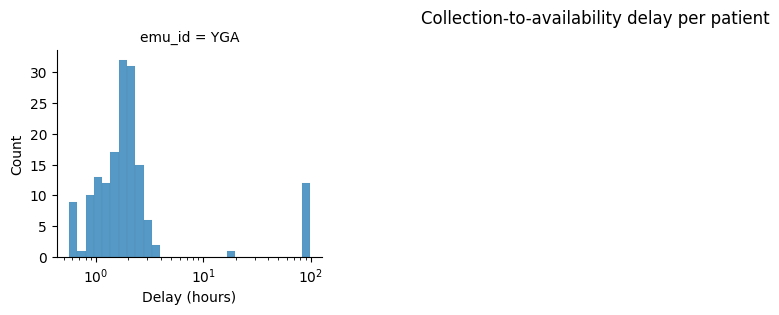

In [6]:
real_delay = stitch_delay.loc[stitch_delay['delay_hours'] < 1.5].copy()
nominal_delay = real_delay.loc[[p in NOMINAL_PATIENTS for p in real_delay['emu_id']]].copy()
print(f'{len(stitch_delay)}/{len(stitched)} task(s) have both timestamps')
print(f'{len(real_delay)} task(s) have potentially real delays')

g = sns.FacetGrid(stitch_delay, col='emu_id', col_wrap=4, sharex=True, sharey=False, height=3)
bins = np.logspace(np.log10(stitch_delay['delay_hours'].min()), np.log10(stitch_delay['delay_hours'].max()), num=30)
g.map(sns.histplot, 'delay_hours', bins=bins)
g.set(xscale='log')
g.set_axis_labels('Delay (hours)', 'Count')
g.figure.suptitle('Collection-to-availability delay per patient', y=1.02)
plt.show()